# 4. Own data

We run the same code (reading, figures, statistics) on a recording we made ourselves with MouseReMoCo.

**Protocol** (inspired by Fauviaux et al., 2021: 2 hands x 3 repetitions):
- participant: Chloé, right-handed;
- one recording of 6 records of 20 s, separated by 20 s pauses (default settings of MouseReMoCo 1.3.0);
- records 1 to 3 with the **right hand** (dominant), records 4 to 6 with the **left hand** (non-dominant);
- the hand was changed during the pause between record 3 and record 4;
- each record started from the same cursor position;
- recorded on a MacBook Air.

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
import os

# interactive plots
%matplotlib widget

# if the working directory is notebooks/, move to the project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

from src import io_mouse as mm
from src import plots as pl

## Analysis functions

The functions that compute the statistics are defined in notebook 03. `%run` executes notebook 03, which makes
its functions available here (`select_record`, `n_laps`, `effective_radius`, `effective_tolerance`, `error_percent`, ...).
It also re-runs notebook 03 on `001MoDe_R1`, which is why its outputs are printed below.

In [2]:
# load the analysis functions of notebook 03 (select_record, n_laps, effective_radius, ...)
# note: this also re-runs notebook 03 on 001MoDe_R1, so its outputs are printed here
%run notebooks/03_analysis.ipynb

Records: 5
Rec      nLaps       Re       Te    error   MT/lap  IDe/lap       Be      IPe
1       -10.84   213.86    91.80     3.90     1.84    14.64     1.95     7.94
ref     -10.85   213.87    91.79     3.90     1.84    14.64     1.95     7.94
2       -11.97   209.85    34.46     0.74     1.59    38.27     0.73    24.04
ref     -11.97   209.85    34.46     0.74     1.59    38.27     0.73    24.04
3       -13.26   209.43    42.42     2.81     1.45    31.02     0.90    21.40
ref     -13.26   209.43    42.42     2.81     1.45    31.02     0.90    21.40
4       -12.83   209.46    37.14     0.13     1.49    35.43     0.79    23.72
ref     -12.83   209.46    37.14     0.13     1.49    35.43     0.79    23.72
5       -14.74   210.89    43.88     2.84     1.30    30.20     0.93    23.20
ref     -14.74   210.89    43.88     2.84     1.30    30.20     0.93    23.20
   nLaps: max difference = 0.012
      Re: max difference = 0.007
      Te: max difference = 0.006
   error: max difference = 0.005

## Loading our recording

Same functions as for `001MoDe_R1`. Two differences with the professor's file:
- **screen**: our screen is larger (1440 x 872 pixels), so the target is larger: task radius 315.5 px instead of 209.5 px,
  with the same tolerance (47 px). The theoretical index of difficulty is therefore higher (about 42 bit instead of 28 bit);
- **software version**: MouseReMoCo 1.3.0 records continuously (also during the pauses) and does not write `0,0,0,0` lines.
  The records are still defined by the `DoRecord` and `DoPause` markers, so the same code works.

In [3]:
DATA_FILE   = "data/own_data.csv"
MARKER_FILE = "data/own_marker.csv"

header = mm.read_header(DATA_FILE)
data = mm.read_data(DATA_FILE, header)
markers, ref_table = mm.read_markers(MARKER_FILE)
records = mm.get_records(markers)

T_TASK = header["taskTolerance"]                          # 47 px
HANDS = ["right", "right", "right", "left", "left", "left"]   # hand used for each record
print("Records:", len(records))
print("Task radius:", header["taskRadius"], "px  |  index of difficulty:", round(header["indexOfDifficulty"], 2), "bit")

Records: 6
Task radius: 315.5 px  |  index of difficulty: 42.18 bit


## Raw time series

`x` and `y` positions during the 6 records. With version 1.3.0, the data is also recorded during the pauses,
but only the samples inside the records are plotted.

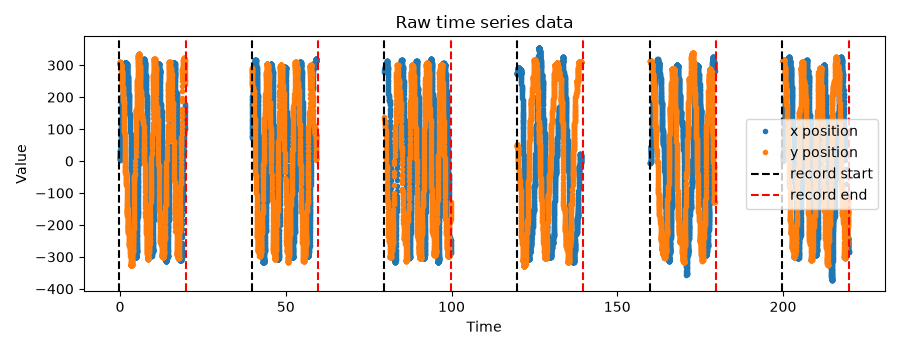

In [4]:
pl.plot_raw_time_series(data, records)

## Raw trajectory

Cursor path for all records (blue), samples inside the target (green) and limits of the target (red).

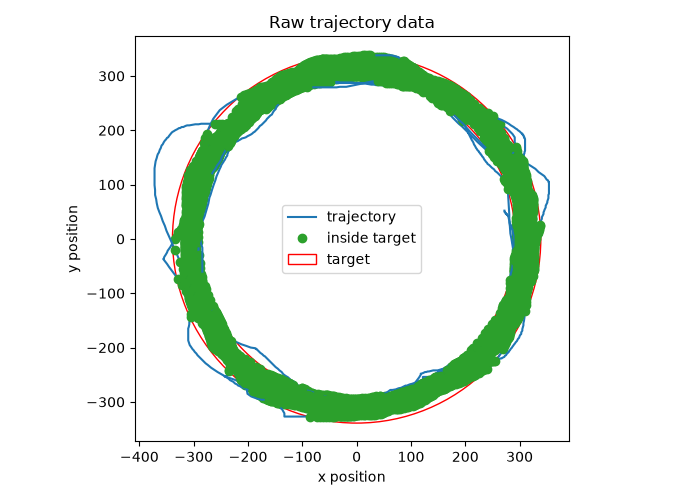

In [5]:
pl.plot_raw_trajectory(data, records, header)

## Records summary

The sampling rate is about 80 to 100 Hz, much lower than in the professor's file (about 199 Hz):
the rate depends on the computer and the mouse (here a MacBook Air), because a sample is only sent when the mouse moves.

In [6]:
pl.print_record_summary(data, records)

Number of records: 6
record 0: 1665 samples from   0.000 to  19.550 s, (19.550s, 85.115 Hz)
record 1: 1601 samples from  39.758 to  59.229 s, (19.471s, 82.173 Hz)
record 2: 1568 samples from  79.772 to  99.767 s, (19.995s, 78.370 Hz)
record 3: 1715 samples from 119.776 to 139.176 s, (19.400s, 88.351 Hz)
record 4: 1912 samples from 159.799 to 179.341 s, (19.542s, 97.789 Hz)
record 5: 1536 samples from 200.025 to 219.786 s, (19.761s, 77.678 Hz)


## Record 1 — right hand (repetition 1)

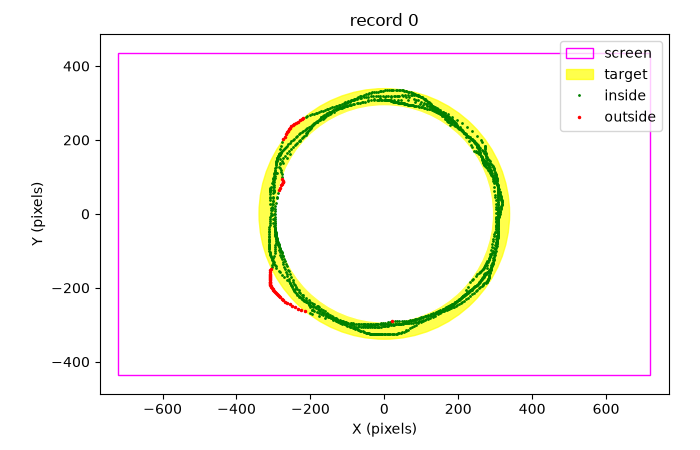

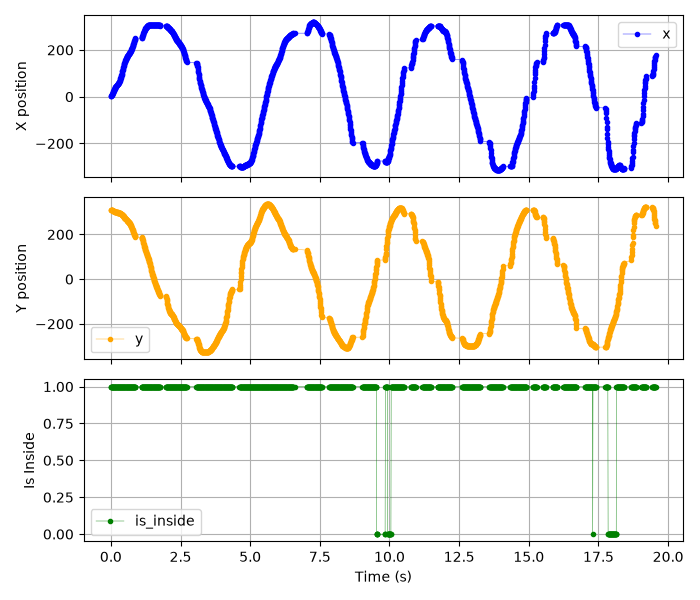

In [7]:
pl.plot_record_trajectory(data, records, header, 0)
pl.plot_record_time_series(data, records, 0)

## Record 2 — right hand (repetition 2)

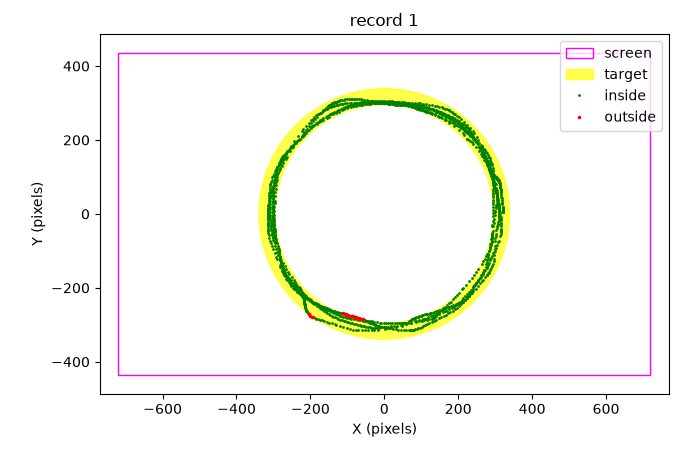

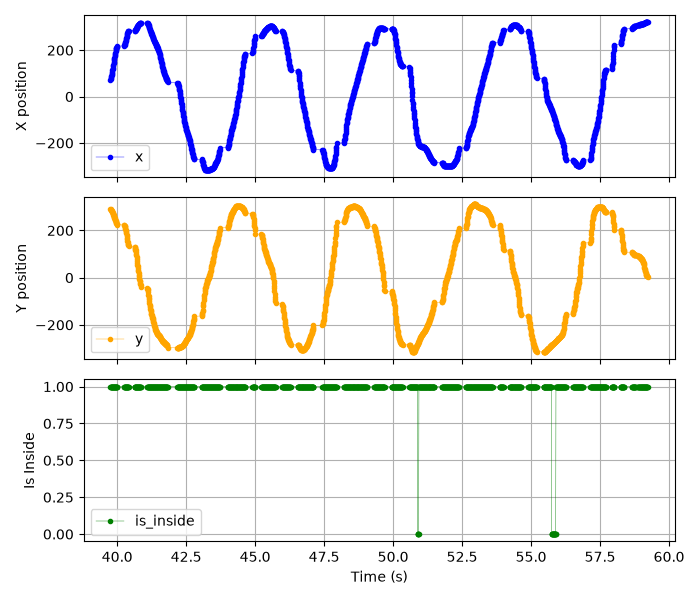

In [8]:
pl.plot_record_trajectory(data, records, header, 1)
pl.plot_record_time_series(data, records, 1)

## Record 3 — right hand (repetition 3)

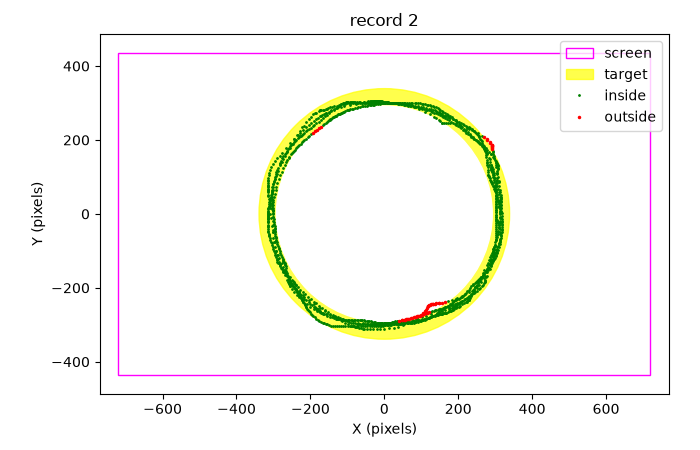

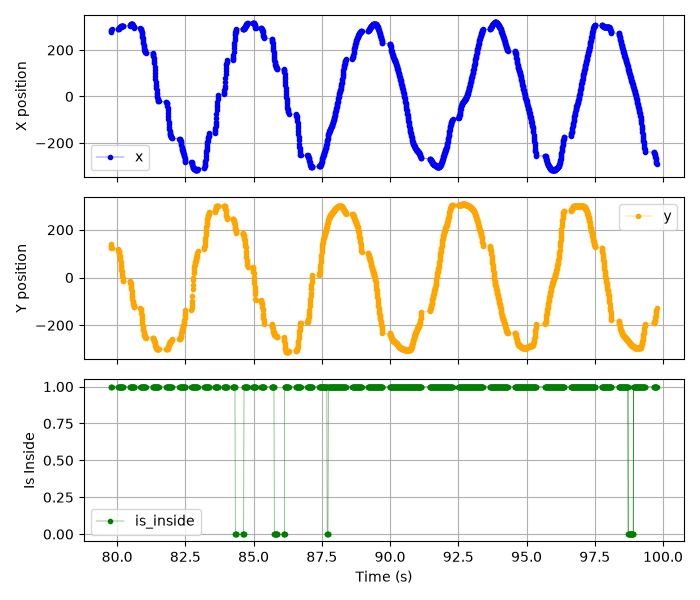

In [9]:
pl.plot_record_trajectory(data, records, header, 2)
pl.plot_record_time_series(data, records, 2)

## Record 4 — left hand (repetition 1)

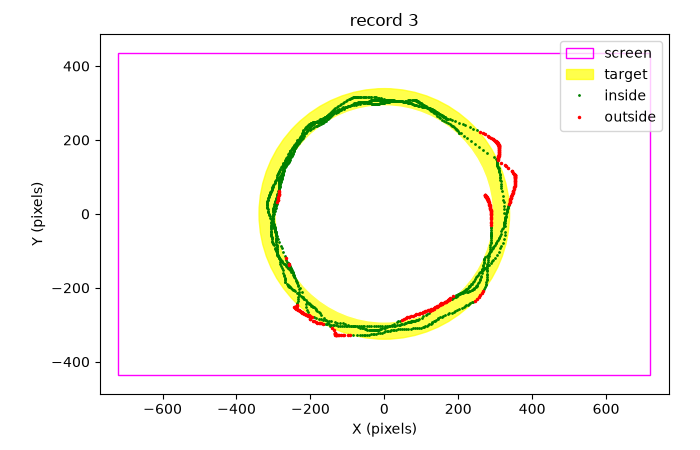

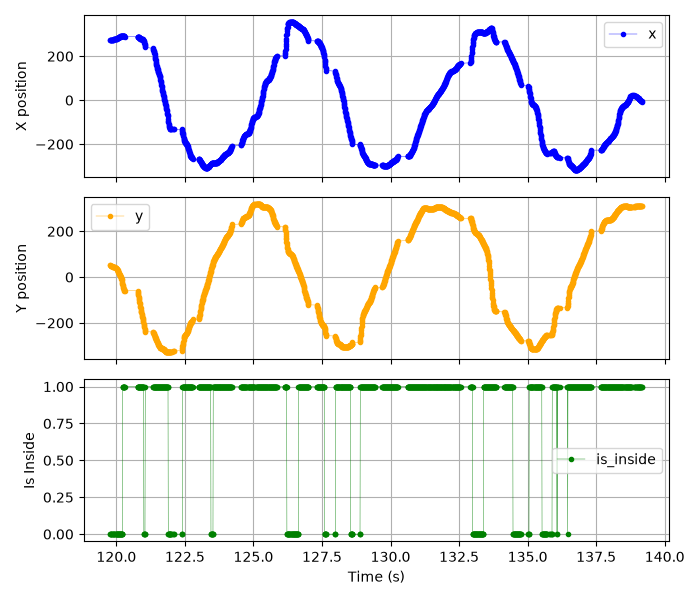

In [10]:
pl.plot_record_trajectory(data, records, header, 3)
pl.plot_record_time_series(data, records, 3)

## Record 5 — left hand (repetition 2)

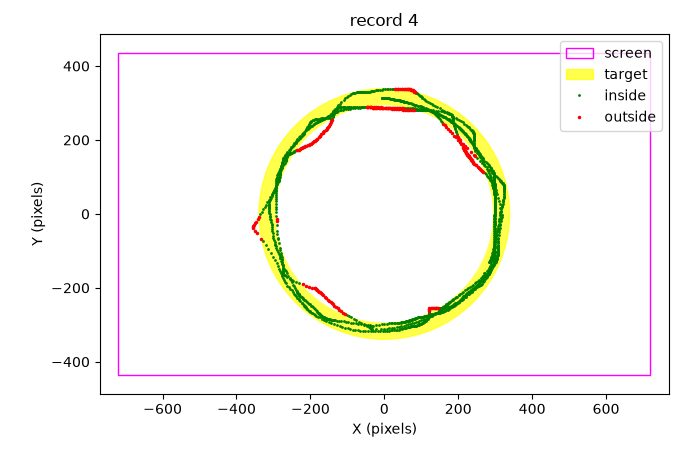

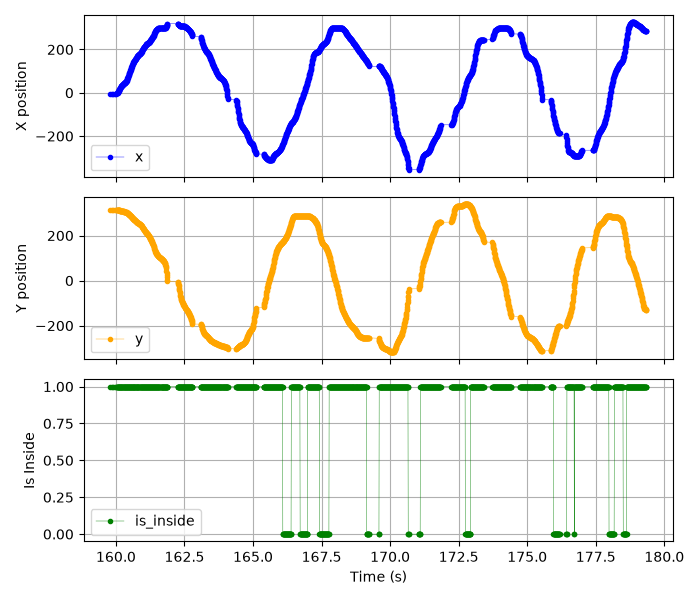

In [11]:
pl.plot_record_trajectory(data, records, header, 4)
pl.plot_record_time_series(data, records, 4)

## Record 6 — left hand (repetition 3)

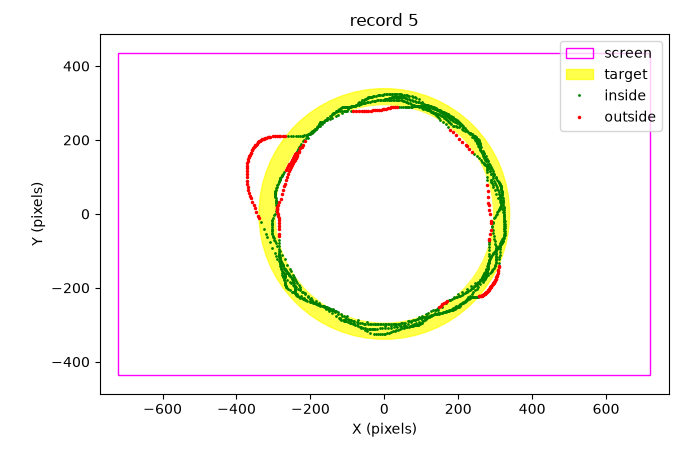

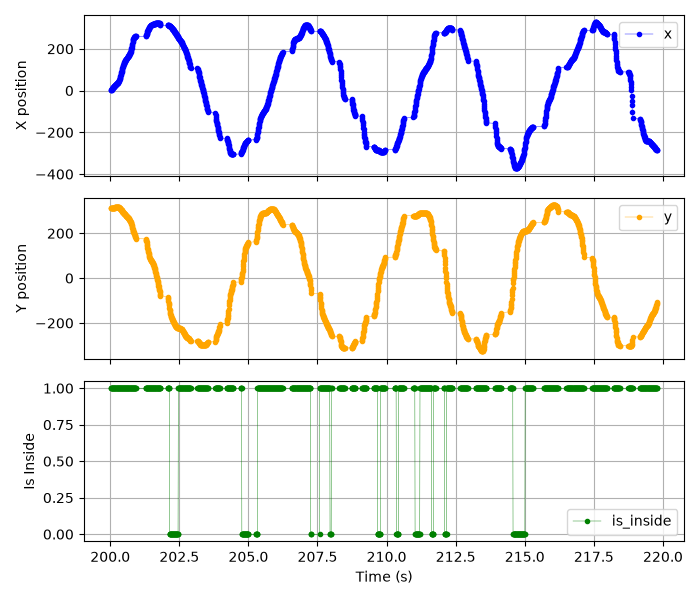

In [12]:
pl.plot_record_trajectory(data, records, header, 5)
pl.plot_record_time_series(data, records, 5)

## Statistics

Same computation as in notebook 03, applied to each record of our recording.

In [13]:
# same computation as in notebook 03, applied to our own recording
results = []
for t_start, t_end in records:
    t, x, y, inside = select_record(data, t_start, t_end)
    laps = n_laps(x, y)
    Re = effective_radius(x, y)
    Te = effective_tolerance(x, y)
    mt = movement_time_per_lap(t, laps)
    ide = ide_per_lap(Re, Te)
    results.append((laps, Re, Te, error_percent(x, y, inside), mt, ide, be(Te, T_TASK), ipe(ide, mt)))

results = np.array(results)

## Comparison with the table written by MouseReMoCo

Our marker file contains the summary table **twice**: MouseReMoCo writes it when the sequence ends
(a key was pressed after the last pause) and again when the software is closed (`q`).
We use the first one: lines 3 to 8 of `ref_table` (Rec001 to Rec006).

In [14]:
# reference table written by MouseReMoCo at the end of the marker file
# (lines 0-2 = Var, unit, Theory; then one line per record)
n = len(records)
ref_rows = [parse_ref(l) for l in ref_table[3:3 + n]]   # Rec001 to Rec006

print("Rec   " + " ".join(f"{name:>8}" for name in names))
for i, row in enumerate(results):
    print(f"{i+1:<5} " + " ".join(f"{v:8.2f}" for v in row))
    print(f"ref   " + " ".join(f"{v:8.2f}" for v in ref_rows[i][1]))

Rec      nLaps       Re       Te    error   MT/lap  IDe/lap       Be      IPe
1        -4.10   313.68    48.08     3.45     4.77    40.99     1.02     8.60
ref      -4.10   313.68    48.08     3.45     4.77    40.99     1.02     8.60
2        -4.21   309.96    37.55     0.99     4.63    51.86     0.80    11.21
ref      -4.21   309.96    37.55     0.99     4.63    51.86     0.80    11.21
3        -4.51   310.27    44.51     2.94     4.44    43.79     0.95     9.87
ref      -4.51   310.27    44.51     2.94     4.44    43.79     0.95     9.87
4        -2.73   312.77    69.54    12.84     6.95    28.26     1.48     4.07
ref      -2.73   312.77    69.54    12.84     6.95    28.26     1.48     4.07
5        -3.32   308.60    57.03    14.99     5.88    34.00     1.21     5.78
ref      -3.32   308.60    57.03    14.99     5.88    34.00     1.21     5.78
6        -3.69   312.64    75.39    15.88     5.35    26.06     1.60     4.87
ref      -3.69   312.64    75.39    15.88     5.35    26.06     

For each column, the difference with the reference must stay small (the reference is rounded to 2 decimals).

In [15]:
ref_values = np.array([r[1] for r in ref_rows])
diff = np.abs(results - ref_values)
for j, name in enumerate(names):
    print(f"{name:>8}: max difference = {diff[:, j].max():.3f}")

   nLaps: max difference = 0.003
      Re: max difference = 0.003
      Te: max difference = 0.005
   error: max difference = 0.005
  MT/lap: max difference = 0.005
 IDe/lap: max difference = 0.005
      Be: max difference = 0.004
     IPe: max difference = 0.003


## Right hand vs left hand

Mean of each variable over the 3 records of each hand.

In [16]:
# mean of each variable for each hand
hands = np.array(HANDS)
print(f"{'':>8} " + " ".join(f"{name:>8}" for name in names))
for hand in ["right", "left"]:
    mean = results[hands == hand].mean(axis=0)
    print(f"{hand:>8} " + " ".join(f"{v:8.2f}" for v in mean))

            nLaps       Re       Te    error   MT/lap  IDe/lap       Be      IPe
   right    -4.27   311.30    43.38     2.46     4.61    45.55     0.92     9.89
    left    -3.25   311.34    67.32    14.57     6.06    29.44     1.43     4.90


IPe and error of each record (blue = right hand, orange = left hand).

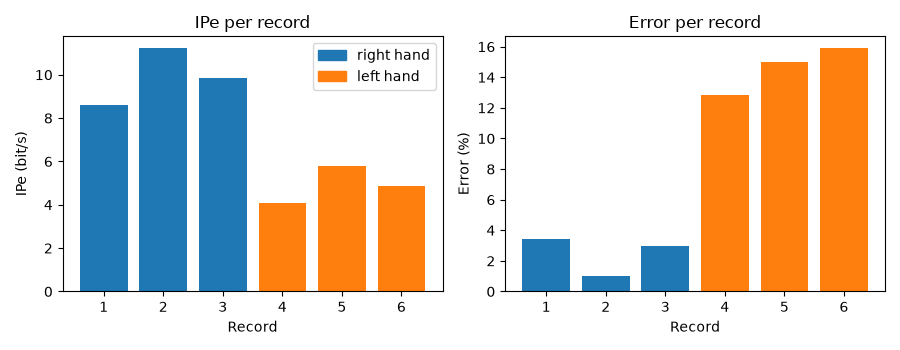

In [17]:
# IPe and error of each record, colored by hand
colors = ["tab:blue" if h == "right" else "tab:orange" for h in HANDS]
rec_numbers = np.arange(1, len(records) + 1)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].bar(rec_numbers, results[:, 7], color=colors)
axs[0].set_title("IPe per record")
axs[0].set_xlabel("Record")
axs[0].set_ylabel("IPe (bit/s)")
axs[1].bar(rec_numbers, results[:, 3], color=colors)
axs[1].set_title("Error per record")
axs[1].set_xlabel("Record")
axs[1].set_ylabel("Error (%)")
axs[0].set_xticks(rec_numbers)
axs[1].set_xticks(rec_numbers)
# legend: one colored square per hand
axs[0].legend(handles=[Rectangle((0, 0), 1, 1, color="tab:blue", label="right hand"),
                       Rectangle((0, 0), 1, 1, color="tab:orange", label="left hand")])
plt.tight_layout()
plt.show()

## Interpretation

With the **left (non-dominant) hand**, the effective index of performance (`IPe`) is about half the one of the right hand,
the error is 4 to 5 times higher, and `Be` is above 1 (the participant used a wider track than required),
whereas with the right hand `Be` stays close to or below 1. This goes in the same direction as Fauviaux et al. (2021):
the effectiveness of visuomotor feedback is lower for the non-dominant hand.

**Limits**:
- The test was realised with one participant only.
- The hands were tested in blocks (3 x right, then 3 x left): the left hand always came after the learning of the task
  and after the fatigue of the right hand, so part of the difference may come from the order, not only from the hand;
- The screen, the target size and the computer differ from the professor's recording, so the values cannot be compared directly
  with `001MoDe_R1`.
- The test was realised without computer mouse but with the trackpad.
